# 08 · Pembuktian Batasan MLP Classifier untuk Image Generation (Tahap 2–5)

**Prasyarat:** notebook **01** (MLP Classifier) dan **02** (Vanilla AE) sudah dijalankan.

Struktur MLP Classifier (784 → 256 → 64) **sama** dengan encoder Autoencoder. Tapi bobot dan fitur latennya **tidak bisa** langsung dipakai untuk membuat gambar. Ada tiga penyebab yang dibuktikan di sini:

| # | Batasan | Penjelasan sederhana | Dibuktikan di |
|---|---|---|---|
| 1 | Cross-Entropy memodelkan **P(y \| x)**, bukan P(x) | Model cuma perlu tahu "ini kelas apa". Detail lain dibuang (*information bottleneck*). | Tahap 4 |
| 2 | **Wᵀ ≠ W⁻¹** dan ReLU memotong nilai negatif | W berbentuk persegi panjang, jadi tidak punya invers. ReLU mengubah semua nilai negatif jadi 0, dan nilai aslinya tidak bisa dikembalikan. | Tahap 2, 3, analisis bobot |
| 3 | Ruang laten tanpa prior **P(z)** | Tidak ada aturan tentang "bentuk" sebaran z, jadi titik acak tidak menjamin gambar yang valid. | Tahap 5 |

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Dataset & MLP Classifier (hasil Tahap 1)

In [2]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_test, y_test = splits["test"]

class MLPClassifier(nn.Module):
    def __init__(self, hidden=(256, 64), n_classes=10):
        super().__init__()
        self.fc1 = nn.Linear(IMG_SIZE, hidden[0])
        self.fc2 = nn.Linear(hidden[0], hidden[1])
        self.fc3 = nn.Linear(hidden[1], n_classes)

    def features(self, x):
        return F.relu(self.fc2(F.relu(self.fc1(x.flatten(1)))))

    def forward(self, x):
        return self.fc3(self.features(x))

ckpt = torch.load(CKPT_DIR / "mlp_classifier.pt", map_location=device)
mlp = MLPClassifier().to(device).eval()
mlp.load_state_dict(ckpt["model"])
for p in mlp.parameters():
    p.requires_grad = False          # bobot MLP dibekukan

W1, W2, W3 = mlp.fc1.weight, mlp.fc2.weight, mlp.fc3.weight
z_mlp = apply_batched(mlp.features, x_test)
summary = {"stage1_test_acc": ckpt["test_acc"]}
print(f"Test accuracy MLP (Tahap 1): {ckpt['test_acc']:.4f}")
print("W1", tuple(W1.shape), "| W2", tuple(W2.shape), "| W3", tuple(W3.shape), "| z_MLP", tuple(z_mlp.shape))

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


C:\Users\Derry\AppData\Local\Temp\ipykernel_14256\2583050669.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(CKPT_DIR / "mlp_classifier.pt", map_locat

Test accuracy MLP (Tahap 1): 0.8899
W1 (256, 784) | W2 (64, 256) | W3 (10, 64) | z_MLP (7000, 64)


## 2. Bukti Matematis Batasan #2: Wᵀ ≠ W⁻¹ dan ReLU Ireversibel

Untuk setiap matriks bobot W (ukuran keluar × masuk):
- **rank** dan **dimensi nullspace**. Contoh: W1 berukuran 256 × 784, jadi rank-nya paling besar 256. Artinya minimal **528 arah** dari ruang input 784 dimensi hilang total. Tidak ada cara mengembalikannya.
- **‖WᵀW − I‖ / ‖I‖**: kalau W ortogonal, nilainya 0 (dan Wᵀ = W⁻¹). Nilai yang jauh dari 0 berarti Wᵀ **bukan** kebalikan W.
- **‖Wᵀ − W⁺‖ / ‖W⁺‖**: seberapa jauh transpos dari *pseudo-inverse* (invers "terbaik" yang mungkin).
- **Persentase aktivasi yang dipotong ReLU** (nilai ≤ 0 → 0).

In [3]:
@torch.no_grad()
def weight_analysis(W):
    W = W.detach().cpu().double()
    out_d, in_d = W.shape
    s = torch.linalg.svdvals(W)
    tol = s.max() * max(W.shape) * torch.finfo(torch.float64).eps
    rank = int((s > tol).sum())
    pinv = torch.linalg.pinv(W)
    I = torch.eye(in_d, dtype=W.dtype)
    return {"shape": [out_d, in_d], "rank": rank, "nullspace_dim_input": in_d - rank,
            "orth_err_WtW": float(torch.linalg.norm(W.T @ W - I) / torch.linalg.norm(I)),
            "condition_number": float(s.max() / s[s > tol].min()),
            "rel_diff_transpose_vs_pinv": float(torch.linalg.norm(W.T - pinv) / torch.linalg.norm(pinv))}

summary["weight_analysis"] = {k: weight_analysis(w) for k, w in [("W1", W1), ("W2", W2), ("W3", W3)]}
with torch.no_grad():
    pre1 = mlp.fc1(x_test[:2000].to(device).flatten(1))
    pre2 = mlp.fc2(F.relu(pre1))
summary["relu_information_loss"] = {"zero_frac_h1": float((pre1 <= 0).float().mean()),
                                    "zero_frac_z": float((pre2 <= 0).float().mean())}
for k, v in summary["weight_analysis"].items():
    print(k, v)
print("ReLU memotong:", summary["relu_information_loss"])

W1 {'shape': [256, 784], 'rank': 256, 'nullspace_dim_input': 528, 'orth_err_WtW': 14.235608854676459, 'condition_number': 37.905482247375076, 'rel_diff_transpose_vs_pinv': 2.499931788201691}
W2 {'shape': [64, 256], 'rank': 64, 'nullspace_dim_input': 192, 'orth_err_WtW': 3.890108075563603, 'condition_number': 16.94787017468165, 'rel_diff_transpose_vs_pinv': 1.4253700954239048}
W3 {'shape': [10, 64], 'rank': 10, 'nullspace_dim_input': 54, 'orth_err_WtW': 1.6522375493715813, 'condition_number': 2.832914828301226, 'rel_diff_transpose_vs_pinv': 2.134850566062634}
ReLU memotong: {'zero_frac_h1': 0.7342343926429749, 'zero_frac_z': 0.4954844117164612}


## 3. Tahap 2: Proyeksi Balik dari Vektor Kelas (Top-Down Weight Transposition)

ẑ = ReLU(W3ᵀ y_c) → ĥ1 = ReLU(W2ᵀ ẑ) → x̂ = Sigmoid(W1ᵀ ĥ1), tanpa training tambahan.

Dugaan: hasilnya berupa **bercak buram**, yaitu gabungan (superposisi) dari "template" bobot kasar, bukan gambar pakaian yang utuh.

{'corr_with_class_mean': [-0.07976097564270443, 0.11429307298969173, 0.16996056768804696, 0.09357179874766454, 0.2805202213119634, 0.22716650660158105, 0.011964402571619482, 0.3382257501909951, 0.13039507248910767, 0.23673858614572188], 'mean_corr_with_class_mean': 0.15230750030936874, 'mean_pairwise_corr_between_classes': 0.2983090635898302, 'classifier_recognizes_own_class': 0.699999988079071}


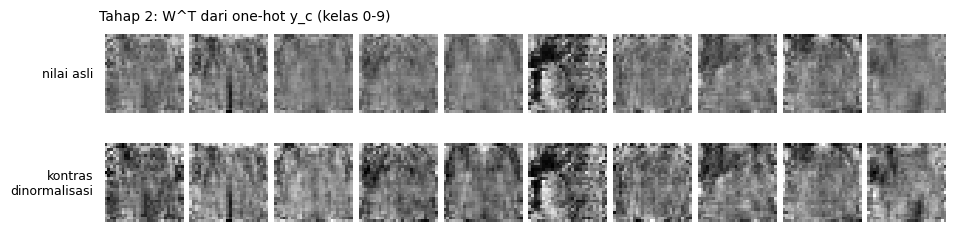

In [4]:
with torch.no_grad():
    Y = torch.eye(10, device=device)                  # 10 vektor one-hot y_c
    z_hat = F.relu(Y @ W3)                            # = (W3^T y_c)^T
    h1_hat = F.relu(z_hat @ W2)                       # = (W2^T z_hat)^T
    x_cls = torch.sigmoid(h1_hat @ W1).view(10, *IMG_SHAPE).cpu()

class_means = torch.stack([x_test[y_test == c].mean(0) for c in range(10)])
flat = x_cls.flatten(1).numpy()
corr_mean = [float(np.corrcoef(flat[c], class_means[c].flatten().numpy())[0, 1]) for c in range(10)]
pair = np.corrcoef(flat)
with torch.no_grad():
    recog = float((mlp(x_cls.to(device)).argmax(1).cpu() == torch.arange(10)).float().mean())
summary["stage2_transpose_from_class"] = {
    "corr_with_class_mean": corr_mean, "mean_corr_with_class_mean": float(np.mean(corr_mean)),
    "mean_pairwise_corr_between_classes": float(pair[np.triu_indices(10, 1)].mean()),
    "classifier_recognizes_own_class": recog}
print(summary["stage2_transpose_from_class"])

def minmax(x):   # kontras dinormalisasi per gambar, hanya untuk tampilan
    lo, hi = x.amin((1, 2, 3), keepdim=True), x.amax((1, 2, 3), keepdim=True)
    return (x - lo) / (hi - lo + 1e-8)

fig, axes = plt.subplots(2, 1, figsize=(11, 2.6))
show_imgs(axes[0], x_cls, label="nilai asli")
show_imgs(axes[1], minmax(x_cls), label="kontras\ndinormalisasi")
axes[0].set_title("Tahap 2: W^T dari one-hot y_c (kelas 0-9)", loc="left")
plt.show()

## 4. Tahap 3: Proyeksi Balik dari Latent Features Citra Uji

x̂ = Sigmoid( W1ᵀ · ReLU(W2ᵀ · z_MLP) )

**Kontrol tambahan:** dicoba juga dengan **pseudo-inverse Moore–Penrose** W⁺, yaitu invers "terbaik" secara least-squares. Kalau cara ini pun gagal, berarti masalahnya bukan sekadar "transpos bukan invers", tetapi **informasinya memang sudah hilang** di dalam jaringan.

W^T          : {'mse': 0.28824689984321594, 'psnr': 5.455574989318848, 'ssim': 0.06562996088353727}
Pseudo-invers: {'mse': 0.18593990802764893, 'psnr': 8.041179656982422, 'ssim': 0.017353633843747024}


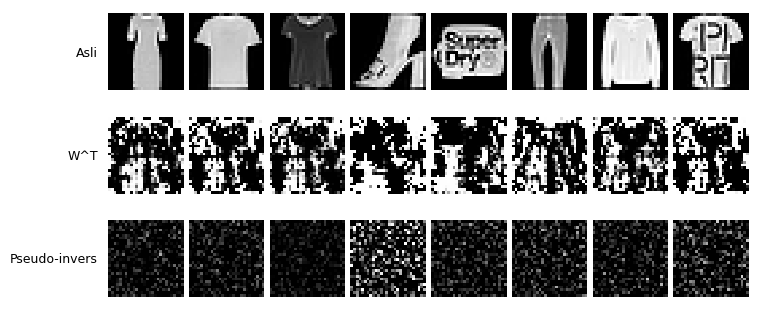

In [5]:
with torch.no_grad():
    tr_fn = lambda z: torch.sigmoid(F.relu(z @ W2) @ W1).view(-1, *IMG_SHAPE)
    W1p, W2p = torch.linalg.pinv(W1), torch.linalg.pinv(W2)
    pinv_fn = lambda z: ((F.relu((z - mlp.fc2.bias) @ W2p.T) - mlp.fc1.bias) @ W1p.T).clamp(0, 1).view(-1, *IMG_SHAPE)
    x_tr = apply_batched(tr_fn, z_mlp)
    x_pinv = apply_batched(pinv_fn, z_mlp)

def quick_metrics(xh, x):
    m = per_image_mse(xh, x)
    return {"mse": float(m.mean()), "psnr": float(psnr_from_mse(m).mean()), "ssim": float(ssim_batch(xh, x).mean())}

summary["stage3_transpose_from_latent"] = quick_metrics(x_tr, x_test)
summary["stage3_control_pseudo_inverse"] = quick_metrics(x_pinv, x_test)
print("W^T          :", summary["stage3_transpose_from_latent"])
print("Pseudo-invers:", summary["stage3_control_pseudo_inverse"])

fig, axes = plt.subplots(3, 1, figsize=(10, 3.8))
show_imgs(axes[0], x_test[:8], label="Asli")
show_imgs(axes[1], x_tr[:8], label="W^T")
show_imgs(axes[2], x_pinv[:8], label="Pseudo-invers")
plt.show()

## 5. Tahap 4: Frozen Latent Decoding (MLP dibekukan, Decoder dilatih dengan MSE)

Decoder 64 → 256 → 784 (arsitekturnya **sama** dengan decoder Vanilla AE) dilatih untuk merekonstruksi gambar dari z_MLP yang **dibekukan**.

Karena decoder diberi kesempatan belajar sebaik mungkin, kalau hasilnya tetap jauh lebih buruk dari Vanilla AE, artinya **informasi detail memang sudah tidak ada di z_MLP**. Informasi itu dibuang oleh Cross-Entropy.

In [6]:
DEC_EPOCHS = n_epochs(30)
decoder = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, IMG_SIZE), nn.Sigmoid()).to(device)
opt = torch.optim.Adam(decoder.parameters(), lr=1e-3)
dec_hist = {"model": "mlp_frozen_decoder", "epoch": [], "train": [], "val": [], "epoch_time_s": [], "iter_loss": []}

for epoch in range(1, DEC_EPOCHS + 1):
    decoder.train(); t0 = time.perf_counter(); tot, n = 0.0, 0
    for it, (x, _) in enumerate(loaders["train"]):
        x = x.to(device)
        with torch.no_grad():
            z = mlp.features(x)                       # z_MLP beku
        loss = F.mse_loss(decoder(z).view_as(x), x)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item(); n += 1
        if it % 10 == 0:
            dec_hist["iter_loss"].append(loss.item())
    decoder.eval()
    with torch.no_grad():
        vl = np.mean([F.mse_loss(decoder(mlp.features(x.to(device))).view_as(x), x.to(device)).item()
                      for x, _ in loaders["val"]])
    dec_hist["epoch"].append(epoch); dec_hist["train"].append({"loss": tot / n}); dec_hist["val"].append({"loss": float(vl)})
    dec_hist["epoch_time_s"].append(time.perf_counter() - t0)
    print(f"Epoch[{epoch}/{DEC_EPOCHS}] Train MSE: {tot / n:.5f}  Val MSE: {vl:.5f}")

rec_mlp_fn = lambda x: decoder(mlp.features(x)).view(-1, *IMG_SHAPE)
summary["stage4_frozen_mlp_decoder"] = reconstruction_metrics(rec_mlp_fn, x_test)
x_rec_mlp = apply_batched(rec_mlp_fn, x_test)
summary["stage4_frozen_mlp_decoder"].update(intra_class_analysis(x_rec_mlp, x_test, y_test))

ae_path = RESULTS_DIR / "metrics" / "vanilla_ae.json"
if ae_path.exists():
    ae = load_json(ae_path)
    summary["stage4_vanilla_ae_same_latent64"] = {k: ae[k] for k in ["mse", "psnr", "ssim"]}
    summary["stage4_vanilla_ae_same_latent64"].update(ae.get("intra_class", {}))
else:
    print("[PERINGATAN] Jalankan notebook 02 (Vanilla AE) dulu untuk perbandingan.")

print(f"{'':28s}{'MSE':>9s}{'PSNR':>8s}{'SSIM':>8s}{'var_ratio':>11s}")
for k, lab in [("stage4_frozen_mlp_decoder", "Frozen decoder z_MLP"), ("stage4_vanilla_ae_same_latent64", "Vanilla AE z_AE")]:
    if k in summary:
        s = summary[k]
        print(f"{lab:28s}{s['mse']:9.5f}{s['psnr']:8.2f}{s['ssim']:8.4f}{s.get('var_ratio', float('nan')):11.3f}")

Epoch[1/30] Train MSE: 0.03668  Val MSE: 0.02740
Epoch[2/30] Train MSE: 0.02519  Val MSE: 0.02382
Epoch[3/30] Train MSE: 0.02278  Val MSE: 0.02247
Epoch[4/30] Train MSE: 0.02155  Val MSE: 0.02146
Epoch[5/30] Train MSE: 0.02070  Val MSE: 0.02073
Epoch[6/30] Train MSE: 0.02015  Val MSE: 0.02021
Epoch[7/30] Train MSE: 0.01965  Val MSE: 0.01982
Epoch[8/30] Train MSE: 0.01928  Val MSE: 0.01954
Epoch[9/30] Train MSE: 0.01898  Val MSE: 0.01928
Epoch[10/30] Train MSE: 0.01871  Val MSE: 0.01904
Epoch[11/30] Train MSE: 0.01853  Val MSE: 0.01886
Epoch[12/30] Train MSE: 0.01834  Val MSE: 0.01872
Epoch[13/30] Train MSE: 0.01818  Val MSE: 0.01862
Epoch[14/30] Train MSE: 0.01801  Val MSE: 0.01862
Epoch[15/30] Train MSE: 0.01788  Val MSE: 0.01829
Epoch[16/30] Train MSE: 0.01776  Val MSE: 0.01821
Epoch[17/30] Train MSE: 0.01766  Val MSE: 0.01810
Epoch[18/30] Train MSE: 0.01755  Val MSE: 0.01798
Epoch[19/30] Train MSE: 0.01746  Val MSE: 0.01821
Epoch[20/30] Train MSE: 0.01736  Val MSE: 0.01809
Epoch[21/

## 6. Tahap 5: Uji Sampling Generatif di Ruang Laten MLP

Hitung μ_z dan σ_z dari z_MLP test set, ambil sampel **z_rand ~ N(μ_z, diag σ_z²)**, lalu decode dengan decoder Tahap 4.

Satu masalah langsung terlihat: z_MLP adalah output **ReLU**, jadi semua nilainya ≥ 0 dan banyak yang tepat 0. Sebaran Gaussian justru menghasilkan banyak nilai **negatif**, yang **tidak pernah muncul** saat training. Decoder pun menerima input yang belum pernah ia lihat.

{'frac_negative_entries': 0.22299374639987946, 'frac_zero_entries_real': 0.4954017996788025, 'mean_max_confidence': 0.7057469487190247, 'mode_coverage': {'class_hist': [0.16940000653266907, 0.033799998462200165, 0.20900000631809235, 0.10260000079870224, 0.12219999730587006, 0.07479999959468842, 0.1387999951839447, 0.03180000185966492, 0.08560000360012054, 0.03200000151991844], 'entropy_norm': 0.925557017326355, 'modes_covered': 10}, 'fid': 143.5057030656377}


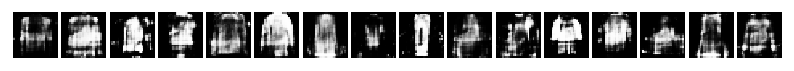

In [7]:
clf = load_mlp_classifier()
z_rand, zstats = gaussian_fit_sampling(z_mlp, FID_NUM_SAMPLES)
x_samp = apply_batched(lambda z: decoder(z).view(-1, *IMG_SHAPE), z_rand)
with torch.no_grad():
    conf = apply_batched(lambda x: F.softmax(mlp(x), 1).max(1).values, x_samp)
summary["stage5_prior_sampling_mlp"] = {**zstats, "mean_max_confidence": float(conf.mean()),
                                        "mode_coverage": mode_coverage(x_samp, clf),
                                        "fid": compute_fid(x_samp, splits)}
print(summary["stage5_prior_sampling_mlp"])
fig, ax = plt.subplots(figsize=(10, 1.4)); show_imgs(ax, x_samp[:16]); plt.show()

## 7. Figur 3: Bukti Empiris Batasan Bobot dan Latent Features MLP Classifier

Empat panel sesuai panduan:
(1) citra asli, (2) proyeksi balik Wᵀ dari y_c dan dari z_MLP, (3) frozen decoder vs Vanilla AE, (4) random prior sampling.

Figur tersimpan: c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results\figures\figure3_mlp_classifier_limitations.png


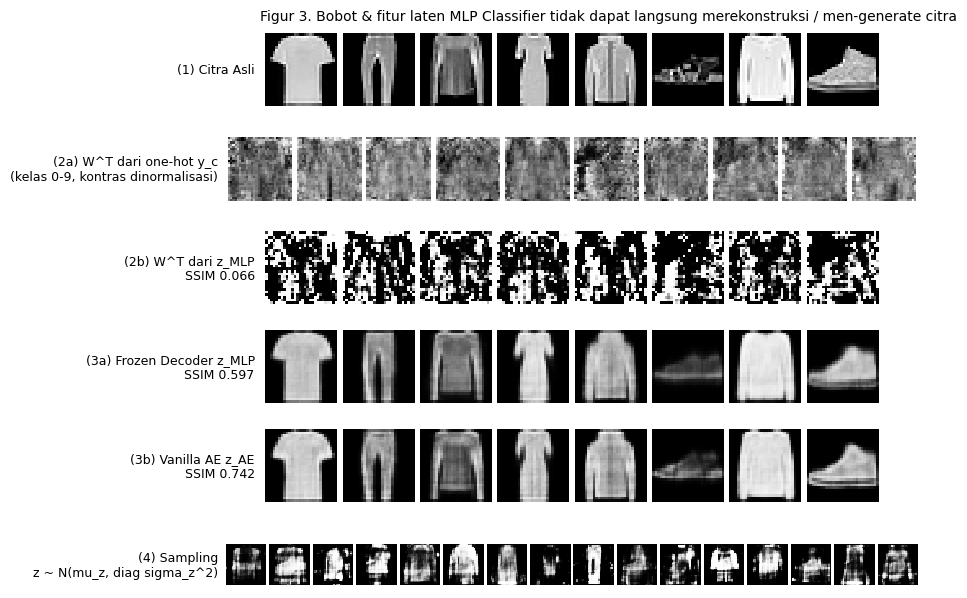

In [8]:
x_fix, _ = fixed_examples(splits)
with torch.no_grad():
    z_fix = mlp.features(x_fix.to(device))
    tr_fix, dec_fix = tr_fn(z_fix).cpu(), rec_mlp_fn(x_fix.to(device)).cpu()
ae_art_path = RESULTS_DIR / "artifacts" / "vanilla_ae.pt"
ae_fix = torch.load(ae_art_path, weights_only=False)["recon_fixed"] if ae_art_path.exists() else None

s = summary
rows = [("(1) Citra Asli", x_fix),
        ("(2a) W^T dari one-hot y_c\n(kelas 0-9, kontras dinormalisasi)", minmax(x_cls)),
        (f"(2b) W^T dari z_MLP\nSSIM {s['stage3_transpose_from_latent']['ssim']:.3f}", tr_fix),
        (f"(3a) Frozen Decoder z_MLP\nSSIM {s['stage4_frozen_mlp_decoder']['ssim']:.3f}", dec_fix)]
if ae_fix is not None:
    rows.append((f"(3b) Vanilla AE z_AE\nSSIM {s['stage4_vanilla_ae_same_latent64']['ssim']:.3f}", ae_fix))
rows.append(("(4) Sampling\nz ~ N(mu_z, diag sigma_z^2)", x_samp[:16]))

fig, axes = plt.subplots(len(rows), 1, figsize=(9, 1.25 * len(rows)))
for ax, (lab, imgs) in zip(axes, rows):
    show_imgs(ax, imgs, label=lab)
axes[0].set_title("Figur 3. Bobot & fitur laten MLP Classifier tidak dapat langsung merekonstruksi / men-generate citra", loc="left")
save_fig(fig, "figure3_mlp_classifier_limitations")
plt.show()

## 8. Simpan Ringkasan

In [9]:
torch.save({"model": decoder.state_dict()}, CKPT_DIR / "mlp_frozen_decoder.pt")
save_results("mlp_experiment", summary, history=dec_hist)
print(json.dumps({k: v for k, v in summary.items() if k != "weight_analysis"}, indent=1, default=float)[:3000])

Hasil 'mlp_experiment' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
{
 "stage1_test_acc": 0.8898571428571429,
 "relu_information_loss": {
  "zero_frac_h1": 0.7342343926429749,
  "zero_frac_z": 0.4954844117164612
 },
 "stage2_transpose_from_class": {
  "corr_with_class_mean": [
   -0.07976097564270443,
   0.11429307298969173,
   0.16996056768804696,
   0.09357179874766454,
   0.2805202213119634,
   0.22716650660158105,
   0.011964402571619482,
   0.3382257501909951,
   0.13039507248910767,
   0.23673858614572188
  ],
  "mean_corr_with_class_mean": 0.15230750030936874,
  "mean_pairwise_corr_between_classes": 0.2983090635898302,
  "classifier_recognizes_own_class": 0.699999988079071
 },
 "stage3_transpose_from_latent": {
  "mse": 0.28824689984321594,
  "psnr": 5.455574989318848,
  "ssim": 0.06562996088353727
 },
 "stage3_control_pseudo_inverse": {
  "mse": 0.18593990802764893,
  "psnr": 8.041179656982422,
  "s